In [14]:
!pip install numpy scipy pandas matplotlib seaborn scikit-learn mne

In [27]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import loadmat
from scipy.signal import butter, filtfilt, iirnotch, welch, detrend

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    auc,
    average_precision_score
)

import time
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully")

All libraries imported successfully


In [16]:
data = loadmat("dataset.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'EEGsample', 'subindex', 'substate'])


In [26]:

EEG = data["EEGsample"]

print("Type:", type(EEG))
print("Shape:", EEG.shape)

Type: <class 'numpy.ndarray'>
Shape: (2022, 30, 384)


In [25]:
print("EEG type:", type(EEG))
print("EEG dimensions:", EEG.ndim)
print("EEG shape:", EEG.shape)
print("Minimum value:", np.min(EEG))
print("Maximum value:", np.max(EEG))
print("Mean:", np.mean(EEG))
print("Standard deviation:", np.std(EEG))

EEG type: <class 'numpy.ndarray'>
EEG dimensions: 3
EEG shape: (2022, 30, 384)
Minimum value: -3195.4259211405174
Maximum value: 3430.9079818460305
Mean: -0.032897111658380135
Standard deviation: 20.014940463647438


In [29]:
print("EEG shape:", EEG.shape)
print("Number of samples:", EEG.shape[0])
print("Number of channels:", EEG.shape[1])
print("Samples per channel:", EEG.shape[2])

print("Subject index shape:", subindex.shape)
print("Subject state shape:", substate.shape)

print("Unique subjects:", np.unique(subindex))
print("Unique states:", np.unique(substate))

EEG shape: (2022, 30, 384)
Number of samples: 2022
Number of channels: 30
Samples per channel: 384
Subject index shape: (2022, 1)
Subject state shape: (2022, 1)
Unique subjects: [ 1  2  3  4  5  6  7  8  9 10 11]
Unique states: [0 1]


In [28]:
subindex = data["subindex"]
substate = data["substate"]

print("EEG shape:", EEG.shape)
print("subindex shape:", subindex.shape)
print("substate shape:", substate.shape)

EEG shape: (2022, 30, 384)
subindex shape: (2022, 1)
substate shape: (2022, 1)


In [30]:
print("Unique subjects:")
print(np.unique(subindex))

print("\nUnique states:")
print(np.unique(substate))


Unique subjects:
[ 1  2  3  4  5  6  7  8  9 10 11]

Unique states:
[0 1]


In [ ]:
print("First 10 subject IDs:")
print(subindex[:10])

print("\nFirst 10 states:")
print(substate[:10])

In [ ]:
sampling freq check

In [31]:
fs = 128   

print("Sampling frequency:", fs, "Hz")

Sampling frequency: 128 Hz


In [20]:
Visualise Raw eeg dataset 

SyntaxError: invalid syntax (338266185.py, line 1)

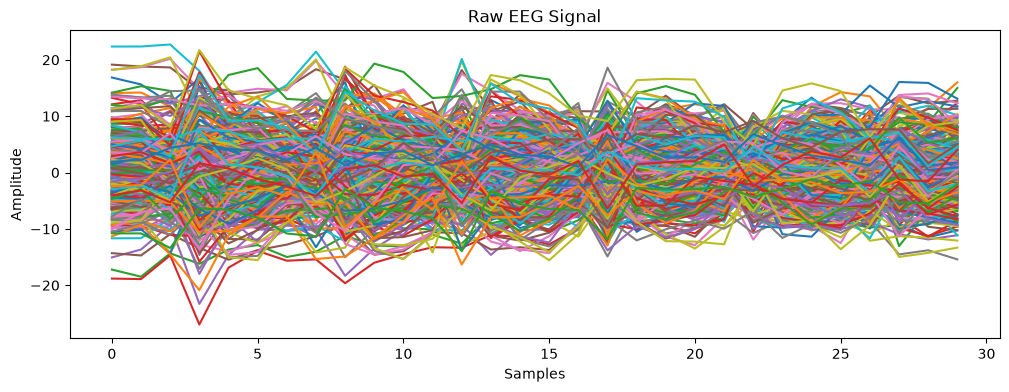

In [32]:
plt.figure(figsize=(12, 4))

plt.plot(EEG[0])

plt.title("Raw EEG Signal")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

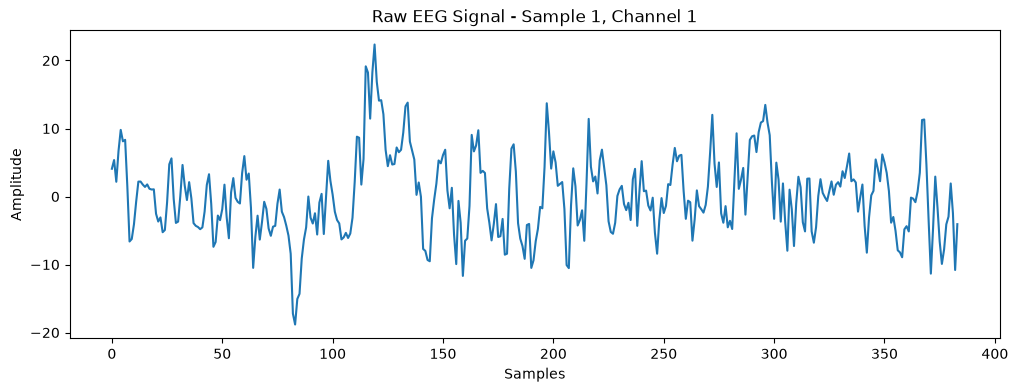

In [33]:
plt.figure(figsize=(12, 4))

plt.plot(EEG[0, 0, :])

plt.title("Raw EEG Signal - Sample 1, Channel 1")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()

In [34]:
def bandpass_filter(signal, lowcut, highcut, fs, order=4):

    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(order, [low, high], btype="band")

    filtered_signal = filtfilt(b, a, signal)

    return filtered_signal

In [35]:
def notch_filter(signal, notch_freq, fs, quality_factor=30):

    nyquist = 0.5 * fs

    w0 = notch_freq / nyquist

    b, a = iirnotch(w0, quality_factor)

    filtered_signal = filtfilt(b, a, signal)

    return filtered_signal

In [36]:
def preprocess_sample(eeg, fs, notch_freq=50):

    # Step 1: Remove baseline drift
    eeg_detrended = detrend(eeg)

    # Step 2: Bandpass filtering
    eeg_bandpass = bandpass_filter(
        eeg_detrended,
        lowcut=0.5,
        highcut=45,
        fs=fs
    )

    # Step 3: Notch filtering
    eeg_clean = notch_filter(
        eeg_bandpass,
        notch_freq=notch_freq,
        fs=fs
    )

    return eeg_clean

In [ ]:
Clean one eeg sample


In [37]:
cleaned_sample = preprocess_sample(EEG[0], fs)

In [38]:
cleaned_sample = preprocess_sample(EEG[0], fs)

print("Original shape:", EEG[0].shape)
print("Cleaned shape:", cleaned_sample.shape)

Original shape: (30, 384)
Cleaned shape: (30, 384)


In [39]:
Plot raw vs cleaned EEG

SyntaxError: invalid syntax (3782777201.py, line 1)

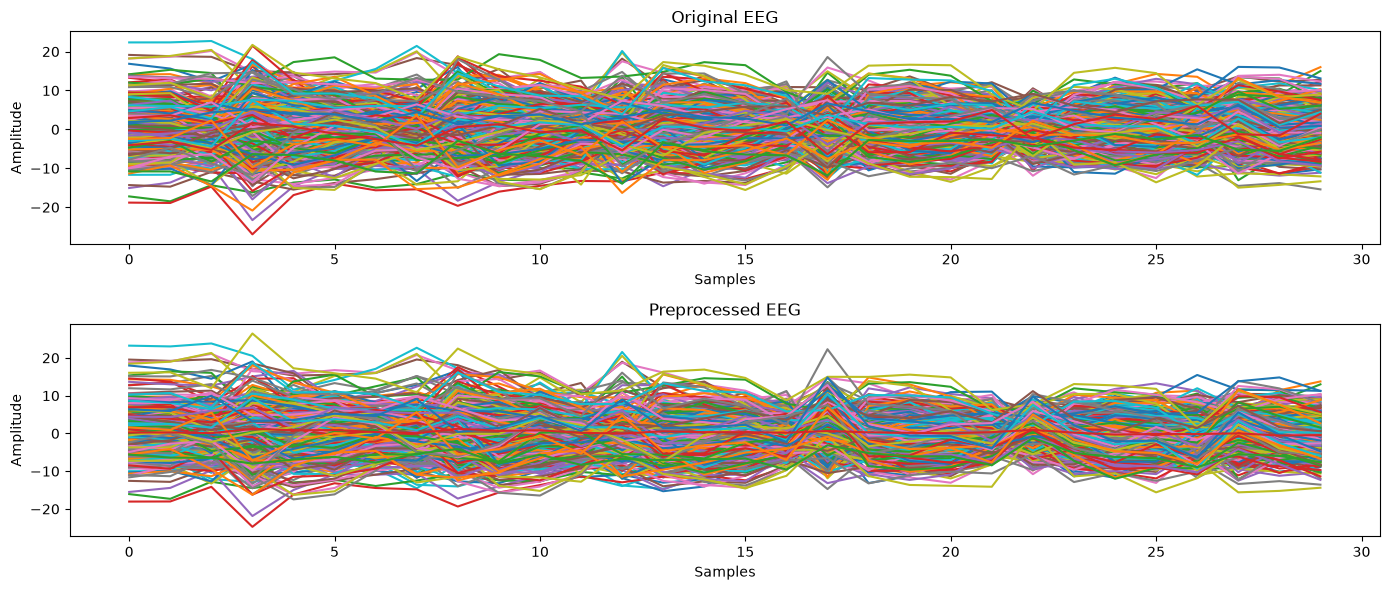

In [40]:
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(EEG[0])
plt.title("Original EEG")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(cleaned_sample)
plt.title("Preprocessed EEG")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [41]:
Sliding window segmentation

SyntaxError: invalid syntax (97850064.py, line 1)

In [42]:
# Fresh window test

signal_test = EEG[0, 0, :]

window_size = 256
stride = 128

print("Signal length:", len(signal_test))
print("Window size:", window_size)
print("Stride:", stride)

windows_test = []

for start in range(0, len(signal_test) - window_size + 1, stride):
    print("Creating window:", start, "to", start + window_size)
    
    window = signal_test[start:start + window_size]
    windows_test.append(window)

print("Number of windows before numpy:", len(windows_test))

windows_test = np.array(windows_test)

print("Final windows shape:", windows_test.shape)

Signal length: 384
Window size: 256
Stride: 128
Creating window: 0 to 256
Creating window: 128 to 384
Number of windows before numpy: 2
Final windows shape: (2, 256)


In [43]:
windows = windows_test

print("Windows shape:", windows.shape)
print("Number of windows:", len(windows))

Windows shape: (2, 256)
Number of windows: 2


In [44]:
bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30)
}

print(bands)

{'delta': (0.5, 4), 'theta': (4, 8), 'alpha': (8, 13), 'beta': (13, 30)}


In [45]:
PSD Signal using welch method

SyntaxError: invalid syntax (3924268615.py, line 1)

In [46]:
from scipy.signal import welch

def calculate_psd(window, fs):
    
    frequencies, psd = welch(
        window,
        fs=fs,
        nperseg=min(len(window), 256)
    )
    
    return frequencies, psd


In [47]:
Test PSD

SyntaxError: invalid syntax (2876101221.py, line 1)

In [48]:
frequencies, psd = calculate_psd(
    windows[0],
    fs
)

print("Frequency shape:", frequencies.shape)
print("PSD shape:", psd.shape)

Frequency shape: (129,)
PSD shape: (129,)


In [49]:
Band Power 

SyntaxError: invalid syntax (858257269.py, line 1)

In [50]:
def band_power(window, fs, low_freq, high_freq):
    
    frequencies, psd = calculate_psd(window, fs)
    
    mask = (
        (frequencies >= low_freq) &
        (frequencies <= high_freq)
    )
    
    power = np.trapezoid(
        psd[mask],
        frequencies[mask]
    )
    
    return power

In [51]:
Extract band power

SyntaxError: invalid syntax (1636437915.py, line 1)

In [52]:
def extract_band_powers(window, fs):
    
    features = {}
    
    for band_name, (low, high) in bands.items():
        
        power = band_power(
            window,
            fs,
            low,
            high
        )
        
        features[band_name] = power
    
    return features

In [53]:
test_features = extract_band_powers(
    windows[0],
    fs
)

print(test_features)

{'delta': np.float64(30.94916534264712), 'theta': np.float64(14.487086512144664), 'alpha': np.float64(7.5585161798198355), 'beta': np.float64(4.130056229887208)}


In [54]:
Relative band power

SyntaxError: invalid syntax (2761739827.py, line 1)

In [55]:
def extract_relative_band_powers(window, fs):
    
    absolute_features = extract_band_powers(window, fs)
    
    total_power = sum(absolute_features.values())
    
    relative_features = {}
    
    for band_name, power in absolute_features.items():
        relative_features[band_name + "_relative"] = power / total_power
    
    return relative_features

In [56]:
Test Relative Band power

SyntaxError: invalid syntax (506322351.py, line 1)

In [57]:
relative_features = extract_relative_band_powers(
    windows[0],
    fs
)

print(relative_features)

{'delta_relative': np.float64(0.5417813663521587), 'theta_relative': np.float64(0.2536040451532366), 'alpha_relative': np.float64(0.13231578875100716), 'beta_relative': np.float64(0.07229879974359764)}


In [58]:
def theta_alpha_ratio(window, fs):
    
    features = extract_band_powers(window, fs)
    
    theta = features["theta"]
    alpha = features["alpha"]
    
    ratio = theta / (alpha + 1e-10)
    
    return ratio

In [59]:
ta_ratio = theta_alpha_ratio(
    windows[0],
    fs
)

print("Theta/Alpha Ratio:", ta_ratio)

Theta/Alpha Ratio: 1.9166574718238298


In [60]:
Different entropy

SyntaxError: invalid syntax (2596280041.py, line 1)

In [61]:
def differential_entropy(window):
    
    variance = np.var(window)
    
    entropy = 0.5 * np.log(
        2 * np.pi * np.e * variance + 1e-10
    )
    
    return entropy

In [62]:
Test DE

SyntaxError: invalid syntax (2460140113.py, line 1)

In [63]:
de = differential_entropy(windows[0])

print("Differential Entropy:", de)

Differential Entropy: 3.2514177300144658


In [64]:
Combine all features

SyntaxError: invalid syntax (2331801893.py, line 1)

In [65]:
def extract_all_features(window, fs):
    
    features = {}
    
    # Absolute band powers
    band_features = extract_band_powers(window, fs)
    features.update(band_features)
    
    # Relative band powers
    relative_features = extract_relative_band_powers(window, fs)
    features.update(relative_features)
    
    # Theta/Alpha ratio
    features["theta_alpha_ratio"] = theta_alpha_ratio(
        window,
        fs
    )
    
    # Differential entropy
    features["differential_entropy"] = differential_entropy(
        window
    )
    
    return features

In [66]:
Test complete extraction

SyntaxError: invalid syntax (3089595174.py, line 1)

In [99]:
all_test_features = extract_all_features( windows[0],fs)
print(all_test_features)

{'delta': np.float64(30.94916534264712), 'theta': np.float64(14.487086512144664), 'alpha': np.float64(7.5585161798198355), 'beta': np.float64(4.130056229887208), 'delta_relative': np.float64(0.5417813663521587), 'theta_relative': np.float64(0.2536040451532366), 'alpha_relative': np.float64(0.13231578875100716), 'beta_relative': np.float64(0.07229879974359764), 'theta_alpha_ratio': np.float64(1.9166574718238298), 'differential_entropy': np.float64(3.2514177300144658)}


In [100]:
from scipy.signal import butter, filtfilt, iirnotch

def preprocess_channel(signal, fs):
    
    # Remove DC offset
    signal = signal - np.mean(signal)
    
    # Bandpass filter: 0.5–45 Hz
    low_freq = 0.5
    high_freq = 45.0
    
    b, a = butter(4,[low_freq / (fs / 2), high_freq / (fs / 2)],btype="band" )
    filtered_signal = filtfilt( b, a, signal)
    # 50 Hz notch filter
    notch_freq = 50.0
    Q = 30.0
    
    b_notch, a_notch = iirnotch(notch_freq / (fs / 2),Q)
    cleaned_signal = filtfilt(
        b_notch,
        a_notch,
        filtered_signal
    )
    
    return cleaned_signal

In [97]:
print("fs =", fs)
print("EEG shape =", EEG.shape)
print("create_windows defined:", "create_windows" in globals())
print("extract_all_features defined:", "extract_all_features" in globals())

fs = 128
EEG shape = (2022, 30, 384)
create_windows defined: False
extract_all_features defined: True


In [105]:
def create_windows(eeg_signal, fs, window_seconds=2, overlap=0.5):

    window_size = int(window_seconds * fs)
    step_size = int(window_size * (1 - overlap))

    windows = []

    for start in range(0, len(eeg_signal) - window_size + 1, step_size):
        end = start + window_size
        windows.append(eeg_signal[start:end])

    return np.array(windows)

In [106]:
all_features = []

for sample_idx in range(5):

    sample_features = []

    for channel_idx in range(EEG.shape[1]):

        eeg_signal = EEG[sample_idx, channel_idx, :]

        # Preprocess
        cleaned_signal = preprocess_channel(eeg_signal, fs)

        # Create windows
        windows_sample = create_windows(
            cleaned_signal,
            fs,
            window_seconds=2,
            overlap=0.5
        )

        # Extract features from each window
        for window in windows_sample:

            features = extract_all_features(window, fs)
            sample_features.append(features)

    all_features.append(sample_features)

print("Number of samples processed:", len(all_features))
print("Features for first sample:", len(all_features[0]))

Number of samples processed: 5
Features for first sample: 60


In [70]:
Feature change into dataframe


SyntaxError: invalid syntax (1236172682.py, line 1)

In [107]:
import pandas as pd

feature_rows = []

for sample_idx, sample_features in enumerate(all_features):
    
    for feature_dict in sample_features:
        
        row = feature_dict.copy()
        row["sample_id"] = sample_idx
        
        feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)

print("Feature DataFrame shape:", features_df.shape)
print(features_df.head())

Feature DataFrame shape: (300, 11)
       delta      theta     alpha      beta  delta_relative  theta_relative  \
0  33.817759  14.485467  7.556854  4.122201        0.563796        0.241496   
1   5.219347   7.596784  3.050437  4.553729        0.255596        0.372021   
2  35.856341  13.348703  6.487628  3.937280        0.601314        0.223859   
3   5.817682   8.211043  2.279882  5.023311        0.272722        0.384918   
4  25.660098  11.784691  5.122078  5.400417        0.534950        0.245682   

   alpha_relative  beta_relative  theta_alpha_ratio  differential_entropy  \
0        0.125985       0.068724           1.916865              3.258566   
1        0.149383       0.223000           2.490392              3.125792   
2        0.108798       0.066029           2.057563              3.249019   
3        0.106877       0.235483           3.601521              3.116480   
4        0.106783       0.112585           2.300764              3.202967   

   sample_id  
0          0

In [72]:
add feature id and data level 

SyntaxError: invalid syntax (2886969262.py, line 1)

In [108]:
subject_ids = np.asarray(subindex).flatten()
states = np.asarray(substate).flatten()

print("Subject IDs:", subject_ids.shape)
print("States:", states.shape)
print("Unique states:", np.unique(states))

Subject IDs: (2022,)
States: (2022,)
Unique states: [0 1]


In [109]:
import pandas as pd

feature_rows = []

for sample_idx, sample_features in enumerate(all_features):
    
    for feature_dict in sample_features:
        
        row = feature_dict.copy()
        row["sample_id"] = sample_idx
        
        feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)

print("Feature DataFrame shape:", features_df.shape)
print(features_df.head())

Feature DataFrame shape: (300, 11)
       delta      theta     alpha      beta  delta_relative  theta_relative  \
0  33.817759  14.485467  7.556854  4.122201        0.563796        0.241496   
1   5.219347   7.596784  3.050437  4.553729        0.255596        0.372021   
2  35.856341  13.348703  6.487628  3.937280        0.601314        0.223859   
3   5.817682   8.211043  2.279882  5.023311        0.272722        0.384918   
4  25.660098  11.784691  5.122078  5.400417        0.534950        0.245682   

   alpha_relative  beta_relative  theta_alpha_ratio  differential_entropy  \
0        0.125985       0.068724           1.916865              3.258566   
1        0.149383       0.223000           2.490392              3.125792   
2        0.108798       0.066029           2.057563              3.249019   
3        0.106877       0.235483           3.601521              3.116480   
4        0.106783       0.112585           2.300764              3.202967   

   sample_id  
0          0

In [110]:
subject_ids = np.asarray(subindex).flatten()
states = np.asarray(substate).flatten()

print("Subject IDs:", subject_ids.shape)
print("States:", states.shape)
print("Unique states:", np.unique(states))


Subject IDs: (2022,)
States: (2022,)
Unique states: [0 1]


In [111]:
rows_per_sample = len(all_features[0])

print("Rows per sample:", rows_per_sample)


Rows per sample: 60


In [112]:
rows_per_sample = len(all_features[0])

print("Rows per sample:", rows_per_sample)

Rows per sample: 60


In [113]:
features_df["subject_id"] = np.repeat(
    subject_ids[:len(all_features)],
    rows_per_sample
)

features_df["state"] = np.repeat(
    states[:len(all_features)],
    rows_per_sample
)

print("Feature DataFrame shape:", features_df.shape)
print(features_df.head())

Feature DataFrame shape: (300, 13)
       delta      theta     alpha      beta  delta_relative  theta_relative  \
0  33.817759  14.485467  7.556854  4.122201        0.563796        0.241496   
1   5.219347   7.596784  3.050437  4.553729        0.255596        0.372021   
2  35.856341  13.348703  6.487628  3.937280        0.601314        0.223859   
3   5.817682   8.211043  2.279882  5.023311        0.272722        0.384918   
4  25.660098  11.784691  5.122078  5.400417        0.534950        0.245682   

   alpha_relative  beta_relative  theta_alpha_ratio  differential_entropy  \
0        0.125985       0.068724           1.916865              3.258566   
1        0.149383       0.223000           2.490392              3.125792   
2        0.108798       0.066029           2.057563              3.249019   
3        0.106877       0.235483           3.601521              3.116480   
4        0.106783       0.112585           2.300764              3.202967   

   sample_id  subject_id  s

In [114]:
print("State distribution:")
print(features_df["state"].value_counts())

print("\nSubject distribution:")
print(features_df["subject_id"].value_counts())

State distribution:
state
0    300
Name: count, dtype: int64

Subject distribution:
subject_id
1    300
Name: count, dtype: int64


In [115]:
print("Number of feature samples:", len(all_features))

for i in range(len(all_features)):
    print(
        "Sample", i,
        "feature rows:", len(all_features[i]),
        "subject:", subject_ids[i],
        "state:", states[i]
    )

Number of feature samples: 5
Sample 0 feature rows: 60 subject: 1 state: 0
Sample 1 feature rows: 60 subject: 1 state: 0
Sample 2 feature rows: 60 subject: 1 state: 0
Sample 3 feature rows: 60 subject: 1 state: 0
Sample 4 feature rows: 60 subject: 1 state: 0


In [116]:
print("First 20 subject IDs:")
print(subject_ids[:20])

print("\nFirst 20 states:")
print(states[:20])

First 20 subject IDs:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

First 20 states:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [117]:
print("Number of samples:", len(all_features))

for i in range(min(5, len(all_features))):
    print(
        f"Sample {i}:",
        "Feature rows =", len(all_features[i]),
        "| Subject ID =", subject_ids[i],
        "| State =", states[i]
    )

Number of samples: 5
Sample 0: Feature rows = 60 | Subject ID = 1 | State = 0
Sample 1: Feature rows = 60 | Subject ID = 1 | State = 0
Sample 2: Feature rows = 60 | Subject ID = 1 | State = 0
Sample 3: Feature rows = 60 | Subject ID = 1 | State = 0
Sample 4: Feature rows = 60 | Subject ID = 1 | State = 0


In [118]:
print("Unique subject IDs:", np.unique(subject_ids))
print("Number of unique subjects:", len(np.unique(subject_ids)))

print("\nUnique states:", np.unique(states))

print("\nFirst 20 subject IDs:")
print(subject_ids[:20])

print("\nFirst 20 states:")
print(states[:20])

Unique subject IDs: [ 1  2  3  4  5  6  7  8  9 10 11]
Number of unique subjects: 11

Unique states: [0 1]

First 20 subject IDs:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

First 20 states:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [119]:
print("Features DataFrame shape:", features_df.shape)

print("\nFirst 5 rows:")
print(features_df.head())

print("\nRows per sample:")
print(features_df.groupby("sample_id").size().head(10))

Features DataFrame shape: (300, 13)

First 5 rows:
       delta      theta     alpha      beta  delta_relative  theta_relative  \
0  33.817759  14.485467  7.556854  4.122201        0.563796        0.241496   
1   5.219347   7.596784  3.050437  4.553729        0.255596        0.372021   
2  35.856341  13.348703  6.487628  3.937280        0.601314        0.223859   
3   5.817682   8.211043  2.279882  5.023311        0.272722        0.384918   
4  25.660098  11.784691  5.122078  5.400417        0.534950        0.245682   

   alpha_relative  beta_relative  theta_alpha_ratio  differential_entropy  \
0        0.125985       0.068724           1.916865              3.258566   
1        0.149383       0.223000           2.490392              3.125792   
2        0.108798       0.066029           2.057563              3.249019   
3        0.106877       0.235483           3.601521              3.116480   
4        0.106783       0.112585           2.300764              3.202967   

   sample_i

In [120]:
print("EEG dataset shape:", EEG.shape)
print("Total samples in dataset:", len(EEG))

print("Number of feature samples:", len(all_features))
print("Number of rows in features_df:", len(features_df))

print("\nUnique subject IDs in dataset:")
print(np.unique(subject_ids))

print("\nUnique states in dataset:")
print(np.unique(states))

print("\nNumber of rows per state:")
print(features_df.groupby("state").size())

print("\nNumber of rows per subject:")
print(features_df.groupby("subject_id").size())


EEG dataset shape: (2022, 30, 384)
Total samples in dataset: 2022
Number of feature samples: 5
Number of rows in features_df: 300

Unique subject IDs in dataset:
[ 1  2  3  4  5  6  7  8  9 10 11]

Unique states in dataset:
[0 1]

Number of rows per state:
state
0    300
dtype: int64

Number of rows per subject:
subject_id
1    300
dtype: int64


In [121]:
print("First 10 feature sample IDs:")
print(sorted(features_df["sample_id"].unique())[:10])

print("\nLast 10 feature sample IDs:")
print(sorted(features_df["sample_id"].unique())[-10:])

print("\nFirst 20 feature rows with labels:")
print(
    features_df[
        ["sample_id", "subject_id", "state"]
    ].head(20)
)

First 10 feature sample IDs:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Last 10 feature sample IDs:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

First 20 feature rows with labels:
    sample_id  subject_id  state
0           0           1      0
1           0           1      0
2           0           1      0
3           0           1      0
4           0           1      0
5           0           1      0
6           0           1      0
7           0           1      0
8           0           1      0
9           0           1      0
10          0           1      0
11          0           1      0
12          0           1      0
13          0           1      0
14          0           1      0
15          0           1      0
16          0           1      0
17          0           1      0
18          0           1      0
19          0           1      0


In [122]:
Verify dataset and features 

SyntaxError: invalid syntax (2103663305.py, line 1)

In [123]:

print("EEG shape:", EEG.shape)
print("Total feature samples:", len(all_features))
print("Feature DataFrame shape:", features_df.shape)

print("\nRows per state:")
print(features_df.groupby("state").size())

print("\nUnique states:", np.unique(states))
print("Unique subject IDs:", np.unique(subject_ids))

print("\nFirst 10 samples with labels:")
print(
    features_df[
        ["sample_id", "subject_id", "state"]
    ].drop_duplicates("sample_id").head(10)
)


EEG shape: (2022, 30, 384)
Total feature samples: 5
Feature DataFrame shape: (300, 13)

Rows per state:
state
0    300
dtype: int64

Unique states: [0 1]
Unique subject IDs: [ 1  2  3  4  5  6  7  8  9 10 11]

First 10 samples with labels:
     sample_id  subject_id  state
0            0           1      0
60           1           1      0
120          2           1      0
180          3           1      0
240          4           1      0


In [124]:

print("Original dataset labels:")
print("Sample 0 — Subject:", subject_ids[0], "| State:", states[0])
print("Sample 1 — Subject:", subject_ids[1], "| State:", states[1])
print("Sample 2 — Subject:", subject_ids[2], "| State:", states[2])

print("\nLabels stored in features_df:")
print(
    features_df.groupby("sample_id")[["subject_id", "state"]]
    .first()
    .head(3)
)


Original dataset labels:
Sample 0 — Subject: 1 | State: 0
Sample 1 — Subject: 1 | State: 0
Sample 2 — Subject: 1 | State: 0

Labels stored in features_df:
           subject_id  state
sample_id                   
0                   1      0
1                   1      0
2                   1      0


In [125]:

# Verify subject IDs and states for every processed sample
label_check = features_df.groupby("sample_id").agg(
    subject_id=("subject_id", "first"),
    state=("state", "first")
)

n = len(label_check)

print("Processed samples:", n)
print("Subject IDs match:", np.array_equal(
    label_check["subject_id"].to_numpy(),
    subject_ids[:n]
))
print("States match:", np.array_equal(
    label_check["state"].to_numpy(),
    states[:n]
))


Processed samples: 5
Subject IDs match: True
States match: True


In [126]:
Extract feature from all eeg samples 

SyntaxError: invalid syntax (1056842925.py, line 1)

In [127]:

all_features_full = []

for sample_idx in range(EEG.shape[0]):
    sample_features = []

    for channel_idx in range(EEG.shape[1]):
        signal = EEG[sample_idx, channel_idx, :]

        cleaned_signal = preprocess_channel(signal, fs)

        windows_sample = create_windows(
            cleaned_signal,
            fs,
            window_seconds=2,
            overlap=0.5
        )

        for window in windows_sample:
            features = extract_all_features(window, fs)
            sample_features.append(features)

    all_features_full.append(sample_features)

    if (sample_idx + 1) % 100 == 0:
        print(f"Processed {sample_idx + 1}/{EEG.shape[0]} samples")

print("\nFeature extraction complete!")
print("Total samples processed:", len(all_features_full))
print("Feature rows for first sample:", len(all_features_full[0]))


Processed 100/2022 samples
Processed 200/2022 samples
Processed 300/2022 samples
Processed 400/2022 samples
Processed 500/2022 samples
Processed 600/2022 samples
Processed 700/2022 samples
Processed 800/2022 samples
Processed 900/2022 samples
Processed 1000/2022 samples
Processed 1100/2022 samples
Processed 1200/2022 samples
Processed 1300/2022 samples
Processed 1400/2022 samples
Processed 1500/2022 samples
Processed 1600/2022 samples
Processed 1700/2022 samples
Processed 1800/2022 samples
Processed 1900/2022 samples
Processed 2000/2022 samples

Feature extraction complete!
Total samples processed: 2022
Feature rows for first sample: 60


Checking feature extraction...
Total samples: 2022
Samples processed: 2022
Features in first sample: 60


In [ ]:
full feature dataframe 

In [130]:

import pandas as pd

feature_rows_full = []

for sample_idx, sample_features in enumerate(all_features_full):
    for feature_dict in sample_features:
        row = feature_dict.copy()

        row["sample_id"] = sample_idx
        row["subject_id"] = subject_ids[sample_idx]
        row["state"] = states[sample_idx]

        feature_rows_full.append(row)

features_df_full = pd.DataFrame(feature_rows_full)

print("Full feature DataFrame created!")
print("Shape:", features_df_full.shape)

print("\nFirst 5 rows:")
print(features_df_full.head())

print("\nRows per sample:")
print(features_df_full.groupby("sample_id").size().head())


Full feature DataFrame created!
Shape: (121320, 13)

First 5 rows:
       delta      theta     alpha      beta  delta_relative  theta_relative  \
0  33.817759  14.485467  7.556854  4.122201        0.563796        0.241496   
1   5.219347   7.596784  3.050437  4.553729        0.255596        0.372021   
2  35.856341  13.348703  6.487628  3.937280        0.601314        0.223859   
3   5.817682   8.211043  2.279882  5.023311        0.272722        0.384918   
4  25.660098  11.784691  5.122078  5.400417        0.534950        0.245682   

   alpha_relative  beta_relative  theta_alpha_ratio  differential_entropy  \
0        0.125985       0.068724           1.916865              3.258566   
1        0.149383       0.223000           2.490392              3.125792   
2        0.108798       0.066029           2.057563              3.249019   
3        0.106877       0.235483           3.601521              3.116480   
4        0.106783       0.112585           2.300764              3.202967

In [ ]:
label verify 

In [131]:

label_check_full = features_df_full.groupby("sample_id").agg(
    subject_id=("subject_id", "first"),
    state=("state", "first")
)

print("Total samples:", len(label_check_full))

print(
    "Subject IDs match:",
    np.array_equal(
        label_check_full["subject_id"].to_numpy(),
        subject_ids
    )
)

print(
    "States match:",
    np.array_equal(
        label_check_full["state"].to_numpy(),
        states
    )
)

print("\nState distribution:")
print(features_df_full.groupby("state").size())


Total samples: 2022
Subject IDs match: True
States match: True

State distribution:
state
0    60660
1    60660
dtype: int64


In [132]:

# Define EEG feature columns
feature_columns = [
    "delta",
    "theta",
    "alpha",
    "beta",
    "delta_relative",
    "theta_relative",
    "alpha_relative",
    "beta_relative",
    "theta_alpha_ratio",
    "differential_entropy"
]

X = features_df_full[feature_columns]
y = features_df_full["state"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:", X.isnull().sum().sum())
print("Infinite values in features:", np.isinf(X.to_numpy()).sum())

print("\nTarget distribution:")
print(y.value_counts().sort_index())


Feature matrix shape: (121320, 10)
Target shape: (121320,)

Missing values in features: 0
Infinite values in features: 0

Target distribution:
state
0    60660
1    60660
Name: count, dtype: int64


In [133]:

from sklearn.model_selection import train_test_split

# One row per original EEG sample
sample_table = (
    features_df_full[
        ["sample_id", "subject_id", "state"]
    ]
    .drop_duplicates("sample_id")
    .reset_index(drop=True)
)

print("Original sample table shape:", sample_table.shape)
print("\nState distribution:")
print(sample_table["state"].value_counts().sort_index())

# Split original sample IDs, not individual feature rows
train_sample_ids, test_sample_ids = train_test_split(
    sample_table["sample_id"],
    test_size=0.2,
    random_state=42,
    stratify=sample_table["state"]
)

train_df = features_df_full[
    features_df_full["sample_id"].isin(train_sample_ids)
].copy()

test_df = features_df_full[
    features_df_full["sample_id"].isin(test_sample_ids)
].copy()

print("\nTraining samples:", len(train_sample_ids))
print("Testing samples:", len(test_sample_ids))
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print(
    "\nAny overlapping sample IDs?",
    not set(train_sample_ids).isdisjoint(set(test_sample_ids))
)


Original sample table shape: (2022, 3)

State distribution:
state
0    1011
1    1011
Name: count, dtype: int64

Training samples: 1617
Testing samples: 405
Training rows: 97020
Testing rows: 24300

Any overlapping sample IDs? False


In [ ]:
Separate input features and target labels

In [134]:


X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df["state"]
y_test = test_df["state"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())


X_train shape: (97020, 10)
X_test shape: (24300, 10)
y_train shape: (97020,)
y_test shape: (24300,)

Missing values in X_train: 0
Missing values in X_test: 0


In [135]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_scaled[:5])


Scaled training shape: (97020, 10)
Scaled testing shape: (24300, 10)

First 5 scaled training rows:
[[-0.01052832 -0.009709   -0.01907606 -0.01637869  0.994042    0.67219643
  -0.70277063 -1.04824629  0.420531   -0.38510601]
 [-0.0123086  -0.01117019 -0.02124944 -0.01626667 -0.68018806  1.92646607
  -0.56958929  0.20080271  0.78524132 -0.63545121]
 [-0.01040141 -0.00995013 -0.01959173 -0.0164267   1.19785308  0.50271821
  -0.8005976  -1.07006625  0.51000193 -0.40310645]
 [-0.01227135 -0.0110399  -0.02162106 -0.01614477 -0.58715526  2.05039771
  -0.81153535  0.3018688   1.49181608 -0.65301045]
 [-0.01103614 -0.01028188 -0.02025031 -0.01604688  0.83734319  0.71242204
  -0.81206942 -0.69313374  0.66465513 -0.48993849]]


In [ ]:
SVM Model

In [136]:

from sklearn.svm import SVC

# Create the SVM classifier
svm_model = SVC(kernel="rbf", C=1.0)

# Train the model
svm_model.fit(X_train_scaled, y_train)

print("SVM model training completed successfully!")


SVM model training completed successfully!


In [ ]:
SVM model evaluation

In [138]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict labels for test data
y_pred = svm_model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("SVM Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


SVM Model Accuracy: 69.47 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.76      0.71     12180
           1       0.72      0.63      0.67     12120

    accuracy                           0.69     24300
   macro avg       0.70      0.69      0.69     24300
weighted avg       0.70      0.69      0.69     24300


Confusion Matrix:
[[9289 2891]
 [4529 7591]]


In [ ]:
Randon forest model

In [139]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using original (unscaled) features
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

# Predict test labels
y_pred_rf = rf_model.predict(X_test)

# Evaluate model
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("\nRandom Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest model training completed!

Random Forest Accuracy: 67.02 %

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.70      0.68     12180
           1       0.68      0.64      0.66     12120

    accuracy                           0.67     24300
   macro avg       0.67      0.67      0.67     24300
weighted avg       0.67      0.67      0.67     24300


Confusion Matrix:
[[8562 3618]
 [4396 7724]]


In [ ]:
comparison table of both model

In [140]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame([
    {
        "Model": "SVM",
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Precision (macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy (%)": accuracy_score(y_test, y_pred_rf) * 100,
        "Precision (macro)": precision_score(
            y_test, y_pred_rf, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, y_pred_rf, average="macro", zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test, y_pred_rf, average="macro", zero_division=0
        )
    }
])

print(results.round(4).to_string(index=False))


        Model  Accuracy (%)  Precision (macro)  Recall (macro)  F1-score (macro)
          SVM       69.4650             0.6982          0.6945            0.6932
Random Forest       67.0206             0.6709          0.6701            0.6698


In [ ]:
Accuracy comparison 

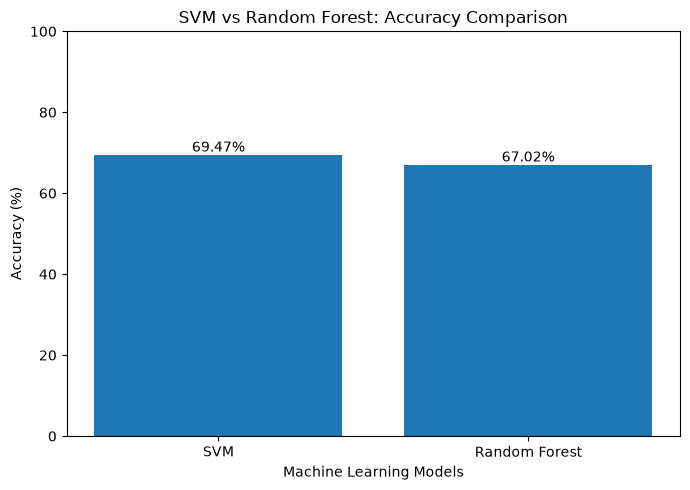

In [143]:

import matplotlib.pyplot as plt

models = results["Model"].tolist()
accuracy = results["Accuracy (%)"].to_numpy()

plt.figure(figsize=(7, 5))

bars = plt.bar(models, accuracy)

plt.title("SVM vs Random Forest: Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.bar_label(bars, fmt="%.2f%%")

plt.tight_layout()
plt.show()


In [ ]:
Metrics Comparison


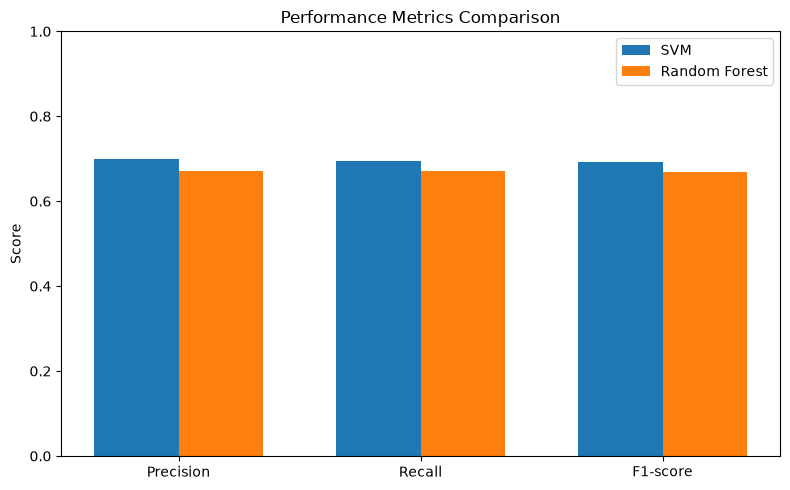

In [144]:

import matplotlib.pyplot as plt
import numpy as np

metric_names = [
    "Precision (macro)",
    "Recall (macro)",
    "F1-score (macro)"
]

x = np.arange(len(metric_names))
width = 0.35

svm_scores = results.loc[0, metric_names].to_numpy(dtype=float)
rf_scores = results.loc[1, metric_names].to_numpy(dtype=float)

plt.figure(figsize=(8, 5))

plt.bar(x - width / 2, svm_scores, width, label="SVM")
plt.bar(x + width / 2, rf_scores, width, label="Random Forest")

plt.xticks(x, ["Precision", "Recall", "F1-score"])
plt.ylabel("Score")
plt.ylim(0, 1)

plt.title("Performance Metrics Comparison")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
confusion matrix comparison

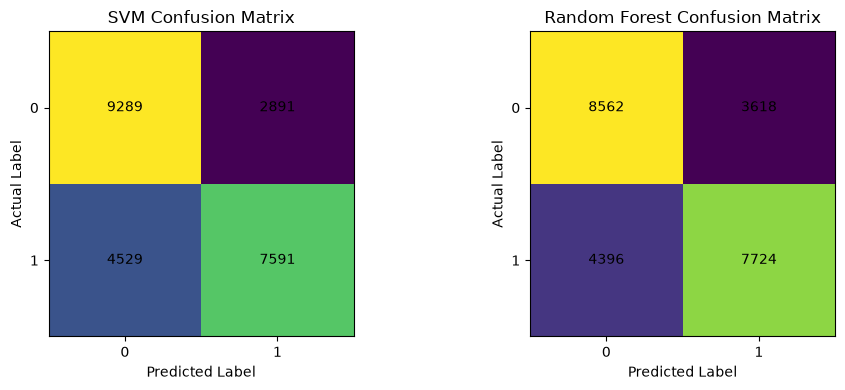

In [145]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_svm = confusion_matrix(y_test, y_pred)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# SVM confusion matrix
axes[0].imshow(cm_svm)
axes[0].set_title("SVM Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])

for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, str(cm_svm[i, j]),
            ha="center", va="center"
        )

# Random Forest confusion matrix
axes[1].imshow(cm_rf)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])

for i in range(2):
    for j in range(2):
        axes[1].text(
            j, i, str(cm_rf[i, j]),
            ha="center", va="center"
        )

plt.tight_layout()
plt.show()


In [ ]:
Subject wise Evaluation

In [ ]:
Check subject 

In [146]:

# Check the number of unique subjects
unique_subjects = np.sort(np.unique(subject_ids))

print("Total subjects:", len(unique_subjects))
print("Subject IDs:", unique_subjects)

print("\nSamples per subject:")
print(
    sample_table.groupby("subject_id")["sample_id"]
    .nunique()
)


Total subjects: 11
Subject IDs: [ 1  2  3  4  5  6  7  8  9 10 11]

Samples per subject:
subject_id
1     188
2     132
3     150
4     148
5     224
6     166
7     102
8     264
9     314
10    108
11    226
Name: sample_id, dtype: int64


In [ ]:
LOSO style evaluation one trial

In [147]:

from sklearn.model_selection import GroupShuffleSplit

# One subject-independent train/test split
groups = sample_table["subject_id"].to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(sample_table, sample_table["state"], groups=groups)
)

train_sample_ids = sample_table.iloc[train_idx]["sample_id"]
test_sample_ids = sample_table.iloc[test_idx]["sample_id"]

train_subjects = sample_table.iloc[train_idx]["subject_id"].unique()
test_subjects = sample_table.iloc[test_idx]["subject_id"].unique()

print("Training subjects:", np.sort(train_subjects))
print("Testing subjects:", np.sort(test_subjects))
print(
    "Subject overlap:",
    not set(train_subjects).isdisjoint(set(test_subjects))
)


Training subjects: [ 2  3  4  5  7  8  9 11]
Testing subjects: [ 1  6 10]
Subject overlap: False


In [ ]:
subject wise training and testing data 

In [148]:

# Create subject-independent train/test datasets

train_df_subject = features_df_full[
    features_df_full["sample_id"].isin(train_sample_ids)
].copy()

test_df_subject = features_df_full[
    features_df_full["sample_id"].isin(test_sample_ids)
].copy()

# Separate features and labels
X_train_subject = train_df_subject[feature_columns]
X_test_subject = test_df_subject[feature_columns]

y_train_subject = train_df_subject["state"]
y_test_subject = test_df_subject["state"]

print("Training subjects:", len(train_subjects))
print("Testing subjects:", len(test_subjects))

print("\nTraining feature shape:", X_train_subject.shape)
print("Testing feature shape:", X_test_subject.shape)

print("\nTraining class distribution:")
print(y_train_subject.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test_subject.value_counts().sort_index())

print(
    "\nSubject overlap:",
    not set(train_subjects).isdisjoint(set(test_subjects))
)


Training subjects: 8
Testing subjects: 3

Training feature shape: (93600, 10)
Testing feature shape: (27720, 10)

Training class distribution:
state
0    46800
1    46800
Name: count, dtype: int64

Testing class distribution:
state
0    13860
1    13860
Name: count, dtype: int64

Subject overlap: False


In [149]:

from sklearn.preprocessing import StandardScaler

scaler_subject = StandardScaler()

X_train_subject_scaled = scaler_subject.fit_transform(
    X_train_subject
)

X_test_subject_scaled = scaler_subject.transform(
    X_test_subject
)

print("Subject-wise scaling completed!")
print("Training shape:", X_train_subject_scaled.shape)
print("Testing shape:", X_test_subject_scaled.shape)


Subject-wise scaling completed!
Training shape: (93600, 10)
Testing shape: (27720, 10)


In [ ]:
Subjectwise training and evaluation

In [150]:

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the SVM model
svm_subject_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train on training subjects
svm_subject_model.fit(
    X_train_subject_scaled,
    y_train_subject
)

print("Subject-wise SVM training completed!")

# Predict on unseen subjects
y_pred_subject = svm_subject_model.predict(
    X_test_subject_scaled
)

# Calculate accuracy
subject_accuracy = accuracy_score(
    y_test_subject,
    y_pred_subject
)

print("\nSubject-wise SVM Accuracy:",
      round(subject_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_subject,
    y_pred_subject,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_subject,
    y_pred_subject
))


Subject-wise SVM training completed!

Subject-wise SVM Accuracy: 70.62 %

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.72      0.71     13860
           1       0.71      0.69      0.70     13860

    accuracy                           0.71     27720
   macro avg       0.71      0.71      0.71     27720
weighted avg       0.71      0.71      0.71     27720


Confusion Matrix:
[[10001  3859]
 [ 4286  9574]]


In [ ]:
subjectwise confusion SVM matrix graph

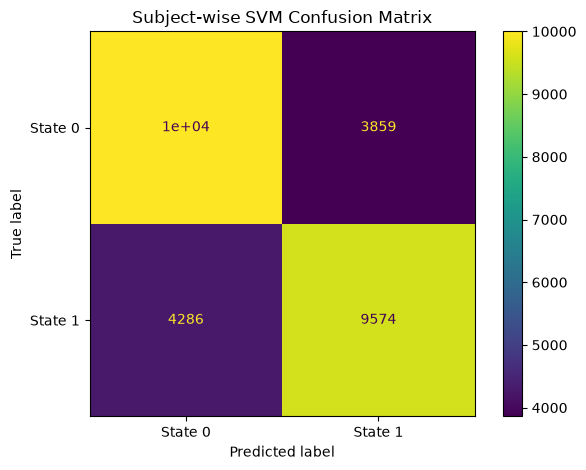

In [151]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_subject = confusion_matrix(
    y_test_subject,
    y_pred_subject
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm_subject,
    display_labels=["State 0", "State 1"]
)

display_cm.plot()
plt.title("Subject-wise SVM Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
LOSO evaluation

In [152]:

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

# Prepare features, labels, and subject groups
X_loso = features_df_full[feature_columns]
y_loso = features_df_full["state"]
groups_loso = features_df_full["subject_id"]

logo = LeaveOneGroupOut()
loso_results = []

# Evaluate each subject separately
for fold, (train_idx, test_idx) in enumerate(
    logo.split(X_loso, y_loso, groups_loso), start=1
):
    X_train_fold = X_loso.iloc[train_idx]
    X_test_fold = X_loso.iloc[test_idx]

    y_train_fold = y_loso.iloc[train_idx]
    y_test_fold = y_loso.iloc[test_idx]

    model = make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, max_iter=5000, random_state=42)
    )

    model.fit(X_train_fold, y_train_fold)
    predictions = model.predict(X_test_fold)

    fold_accuracy = accuracy_score(y_test_fold, predictions)
    test_subject = groups_loso.iloc[test_idx].unique()[0]

    loso_results.append({
        "Subject": int(test_subject),
        "Test Samples": int(
            features_df_full.iloc[test_idx]["sample_id"].nunique()
        ),
        "Accuracy (%)": fold_accuracy * 100
    })

    print(f"Fold {fold}/11 | Subject {test_subject} | " f"Accuracy: {fold_accuracy * 100:.2f}%" )

loso_df = pd.DataFrame(loso_results)

print("\nLOSO results for all subjects:")
print(loso_df.round(2).to_string(index=False))

print("\nMean LOSO accuracy:",round(loso_df["Accuracy (%)"].mean(), 2), "%")

print("Standard deviation:",   round(loso_df["Accuracy (%)"].std(), 2), "%")


Fold 1/11 | Subject 1 | Accuracy: 68.84%
Fold 2/11 | Subject 2 | Accuracy: 51.77%
Fold 3/11 | Subject 3 | Accuracy: 57.93%
Fold 4/11 | Subject 4 | Accuracy: 62.64%
Fold 5/11 | Subject 5 | Accuracy: 62.95%
Fold 6/11 | Subject 6 | Accuracy: 68.32%
Fold 7/11 | Subject 7 | Accuracy: 56.36%
Fold 8/11 | Subject 8 | Accuracy: 64.29%
Fold 9/11 | Subject 9 | Accuracy: 75.43%
Fold 10/11 | Subject 10 | Accuracy: 78.38%
Fold 11/11 | Subject 11 | Accuracy: 57.96%

LOSO results for all subjects:
 Subject  Test Samples  Accuracy (%)
       1           188         68.84
       2           132         51.77
       3           150         57.93
       4           148         62.64
       5           224         62.95
       6           166         68.32
       7           102         56.36
       8           264         64.29
       9           314         75.43
      10           108         78.38
      11           226         57.96

Mean LOSO accuracy: 64.08 %
Standard deviation: 8.15 %


In [ ]:
Subjectwise accuracy graph

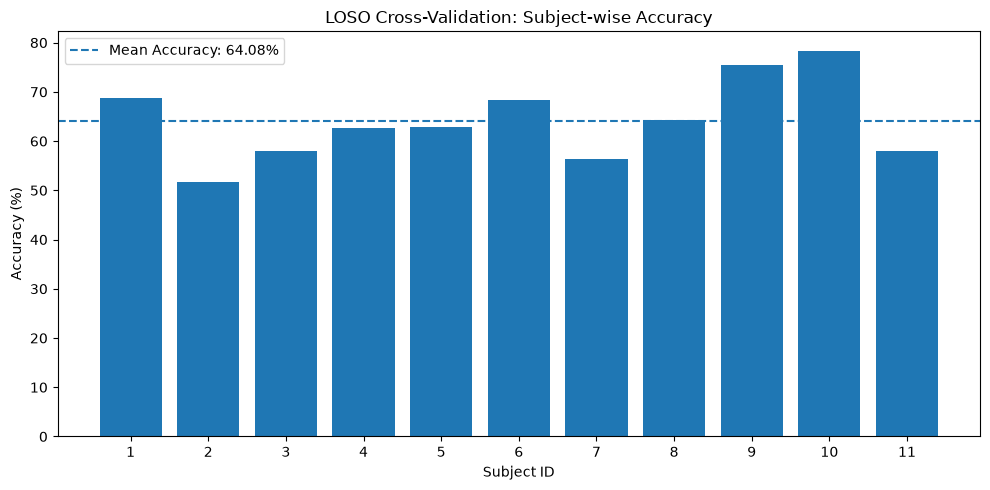

In [153]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    loso_df["Subject"].astype(str),
    loso_df["Accuracy (%)"]
)

plt.axhline(
    y=loso_df["Accuracy (%)"].mean(),
    linestyle="--",
    label="Mean Accuracy: 64.08%"
)

plt.xlabel("Subject ID")
plt.ylabel("Accuracy (%)")
plt.title("LOSO Cross-Validation: Subject-wise Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
LOSO Summary

In [154]:

print("FINAL LOSO SUMMARY")
print("------------------")
print(f"Mean Accuracy: {loso_df['Accuracy (%)'].mean():.2f}%")
print(f"Best Subject Accuracy: {loso_df['Accuracy (%)'].max():.2f}%")
print(f"Lowest Subject Accuracy: {loso_df['Accuracy (%)'].min():.2f}%")
print(f"Standard Deviation: {loso_df['Accuracy (%)'].std():.2f}%")


FINAL LOSO SUMMARY
------------------
Mean Accuracy: 64.08%
Best Subject Accuracy: 78.38%
Lowest Subject Accuracy: 51.77%
Standard Deviation: 8.15%


In [ ]:
final comparison table 

In [157]:

import pandas as pd

final_results = pd.DataFrame([
    {
        "Evaluation Method": "Random Sample Split",
        "Model": "RBF SVM",
        "Accuracy (%)": 69.47
    },
    {
        "Evaluation Method": "Random Sample Split",
        "Model": "Random Forest",
        "Accuracy (%)": 67.02
    },
    {
        "Evaluation Method": "Subject-wise Split",
        "Model": "Linear SVM",
        "Accuracy (%)": 70.62
    },
    {
        "Evaluation Method": "LOSO Cross-Validation",
        "Model": "Linear SVM",
        "Accuracy (%)": 64.08
    }
])
display(final_results.style.hide(axis="index"))




Evaluation Method,Model,Accuracy (%)
Random Sample Split,RBF SVM,69.470000
Random Sample Split,Random Forest,67.020000
Subject-wise Split,Linear SVM,70.620000
LOSO Cross-Validation,Linear SVM,64.080000


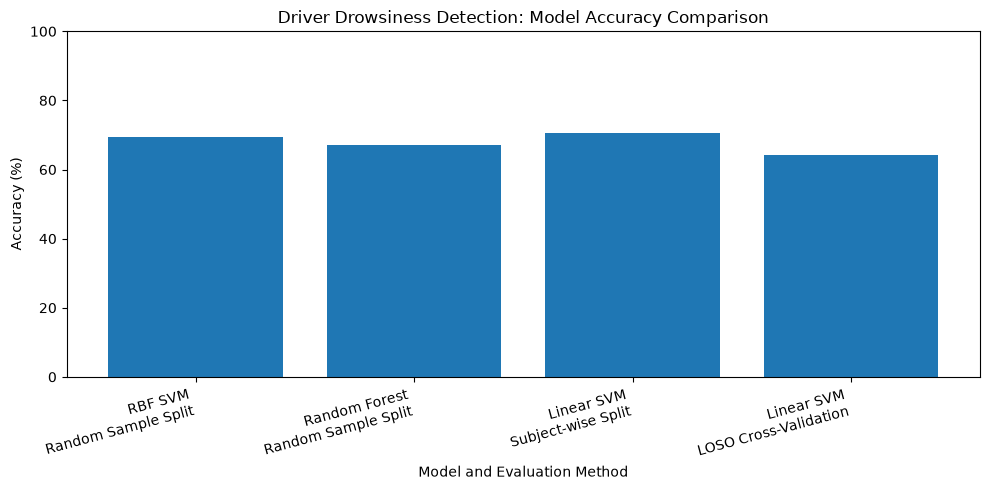

In [158]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    final_results["Model"] + "\n" + final_results["Evaluation Method"],
    final_results["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model and Evaluation Method")
plt.title("Driver Drowsiness Detection: Model Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
overall matrics of LOSO

In [160]:

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

X_loso = features_df_full[feature_columns]
y_loso = features_df_full["state"]
groups_loso = features_df_full["subject_id"]

logo = LeaveOneGroupOut()

loso_predictions = np.empty(len(y_loso), dtype=int)
loso_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X_loso, y_loso, groups_loso), start=1
):
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(C=1.0, max_iter=5000, random_state=42)
    )

    model.fit(X_loso.iloc[train_idx], y_loso.iloc[train_idx])

    predictions = model.predict(X_loso.iloc[test_idx])
    loso_predictions[test_idx] = predictions

    actual = y_loso.iloc[test_idx]
    subject = int(groups_loso.iloc[test_idx].iloc[0])

    loso_results.append({
        "Subject": subject,
        "Accuracy (%)": accuracy_score(actual, predictions) * 100
    })

print("All 11 LOSO folds completed.")
print("Actual labels:", len(y_loso))
print("Predictions:", len(loso_predictions))


All 11 LOSO folds completed.
Actual labels: 121320
Predictions: 121320


In [163]:

print("LOSO Overall Classification Report")

print(classification_report(
    y_loso,
    loso_predictions,
    labels=[0, 1],
    target_names=["State 0", "State 1"],
    digits=4
))


LOSO Overall Classification Report
              precision    recall  f1-score   support

     State 0     0.6417    0.6732    0.6570     60660
     State 1     0.6563    0.6241    0.6398     60660

    accuracy                         0.6486    121320
   macro avg     0.6490    0.6486    0.6484    121320
weighted avg     0.6490    0.6486    0.6484    121320



In [ ]:
LOSO confusion matrix

LOSO Confusion Matrix:
[[40834 19826]
 [22805 37855]]


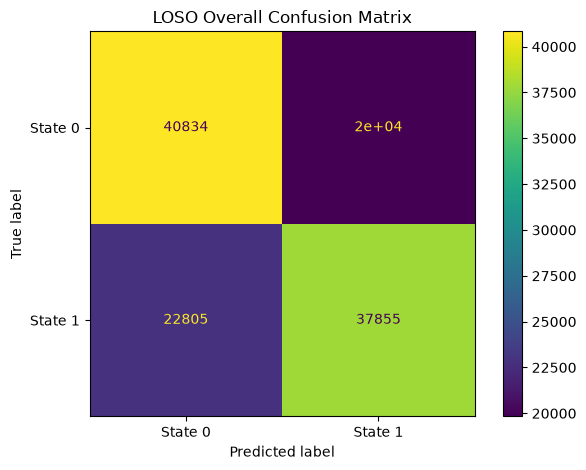

In [164]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_loso = confusion_matrix(y_loso, loso_predictions, labels=[0, 1])

print("LOSO Confusion Matrix:")
print(cm_loso)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_loso,
    display_labels=["State 0", "State 1"]
)

disp.plot()
plt.title("LOSO Overall Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
original sample prediction 

In [166]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Actual label and predicted label for each feature row
row_results = pd.DataFrame({
    "sample_id": features_df_full["sample_id"].to_numpy(),
    "actual_state": y_loso.to_numpy(),
    "predicted_state": loso_predictions
})

# Check whether each original sample has only one actual label
label_counts = row_results.groupby("sample_id")["actual_state"].nunique()
print("Samples with inconsistent actual labels:", (label_counts > 1).sum())

# Aggregate 60 feature-row predictions into one sample prediction
sample_results = row_results.groupby("sample_id").agg(
    actual_state=("actual_state", "first"),
    predicted_state=("predicted_state", lambda x: x.mode().iloc[0])
).reset_index()

print("Original EEG samples:", len(sample_results))

print("\nSample-Level Classification Report")
print(classification_report(
    sample_results["actual_state"],
    sample_results["predicted_state"],
    labels=[0, 1],
    target_names=["State 0", "State 1"],
    digits=4
))

print("Sample-Level Accuracy:",
      round(accuracy_score(
          sample_results["actual_state"],
          sample_results["predicted_state"]
      ) * 100, 2), "%")

print("\nSample-Level Confusion Matrix:")
print(confusion_matrix(
    sample_results["actual_state"],
    sample_results["predicted_state"],
    labels=[0, 1]
))


Samples with inconsistent actual labels: 0
Original EEG samples: 2022

Sample-Level Classification Report
              precision    recall  f1-score   support

     State 0     0.6870    0.7141    0.7003      1011
     State 1     0.7024    0.6746    0.6882      1011

    accuracy                         0.6944      2022
   macro avg     0.6947    0.6944    0.6942      2022
weighted avg     0.6947    0.6944    0.6942      2022

Sample-Level Accuracy: 69.44 %

Sample-Level Confusion Matrix:
[[722 289]
 [329 682]]


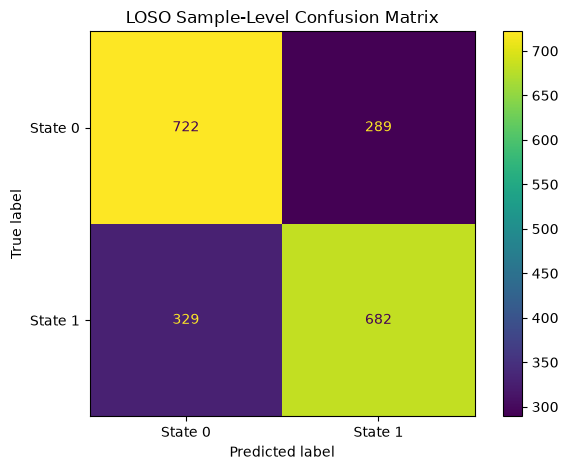

In [167]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm_sample = confusion_matrix(
    sample_results["actual_state"],
    sample_results["predicted_state"],
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_sample,
    display_labels=["State 0", "State 1"]
)

disp.plot()
plt.title("LOSO Sample-Level Confusion Matrix")
plt.tight_layout()
plt.show()


In [168]:

final_evaluation = pd.DataFrame([
    {
        "Evaluation": "Random Sample Split",
        "Model": "RBF SVM",
        "Accuracy (%)": 69.47,
        "Level": "Feature rows"
    },
    {
        "Evaluation": "Random Sample Split",
        "Model": "Random Forest",
        "Accuracy (%)": 67.02,
        "Level": "Feature rows"
    },
    {
        "Evaluation": "Subject-wise Split",
        "Model": "Linear SVM",
        "Accuracy (%)": 70.62,
        "Level": "Feature rows"
    },
    {
        "Evaluation": "LOSO Cross-Validation",
        "Model": "Linear SVM",
        "Accuracy (%)": 64.08,
        "Level": "Mean subject accuracy"
    },
    {
        "Evaluation": "LOSO Cross-Validation",
        "Model": "Linear SVM + majority vote",
        "Accuracy (%)": 69.44,
        "Level": "Original EEG samples"
    }
])

display(final_evaluation.style.hide(axis="index").format({
    "Accuracy (%)": "{:.2f}%"
}))


Evaluation,Model,Accuracy (%),Level
Random Sample Split,RBF SVM,69.47%,Feature rows
Random Sample Split,Random Forest,67.02%,Feature rows
Subject-wise Split,Linear SVM,70.62%,Feature rows
LOSO Cross-Validation,Linear SVM,64.08%,Mean subject accuracy
LOSO Cross-Validation,Linear SVM + majority vote,69.44%,Original EEG samples


In [ ]:
Dataset label distribution 

In [169]:

print("State distribution in original samples:")
print(
    features_df_full.groupby("sample_id")["state"]
    .first()
    .value_counts()
    .sort_index()
)

print("\nUnique states:", sorted(features_df_full["state"].unique()))
print("Unique subjects:", sorted(features_df_full["subject_id"].unique()))


State distribution in original samples:
state
0    1011
1    1011
Name: count, dtype: int64

Unique states: [np.uint8(0), np.uint8(1)]
Unique subjects: [np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11)]


In [170]:

from sklearn.metrics import classification_report

print("Sample-Level Driver Drowsiness Detection Report")

print(classification_report(
    sample_results["actual_state"],
    sample_results["predicted_state"],
    labels=[0, 1],
    target_names=["Alert", "Drowsy"],
    digits=4
))


Sample-Level Driver Drowsiness Detection Report
              precision    recall  f1-score   support

       Alert     0.6870    0.7141    0.7003      1011
      Drowsy     0.7024    0.6746    0.6882      1011

    accuracy                         0.6944      2022
   macro avg     0.6947    0.6944    0.6942      2022
weighted avg     0.6947    0.6944    0.6942      2022



In [171]:
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Final model for the UI prototype
final_model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=1.0, max_iter=5000, random_state=42)
)

# Train using the existing extracted EEG features
final_model.fit(
    features_df_full[feature_columns],
    features_df_full["state"]
)

# Save the trained model
joblib.dump(final_model, "drowsiness_model.joblib")

print("Model saved successfully!")

Model saved successfully!
